In [1]:
import os
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import fiona

fiona.drvsupport.supported_drivers["KML"] = (
    "rw"  # enable KML support which is disabled by default
)

from utilities import get_geo_nn, make_folder, walk_through_files

import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_rows", 500)

In [2]:
# SUBZONE_SHP2014_FILE = os.path.join('zip://', '..', 'raw-files', 'master-plan-2014-subzone-boundary-no-sea', 'master-plan-2014-subzone-boundary-no-sea-shp.zip')
SUBZONE_KML2014_FILE = os.path.join(
    "zip://",
    "raw-data",
    "master-plan-2014-subzone-boundary-no-sea",
    "master-plan-2014-subzone-boundary-no-sea-kml.zip",
)
SWEAT_FILEPATH = os.path.join("raw-data", "SWEAT", "datafiles")
FP_WEATHER = os.path.join("raw-data", "SWEAT", "datafiles", "weather")
CROSSWALK_SAVEPATH = os.path.join(
    "intermediate-files", "subzones2014-weatherstation-crosswalk.csv"
)

SAVEPATH = os.path.join("..", "results", "figures", "supplementary")
make_folder(SAVEPATH)

../results/figures/supplementary already exists.


### Read in subzones

In [3]:
subzones = (
    gpd.read_file(SUBZONE_KML2014_FILE)
    .assign(centroid=lambda df: df.centroid)
    .rename(columns={"Name": "subzone"})
    .query('subzone!="NORTH-EASTERN ISLANDS"')
    .query('subzone!="JURONG ISLAND AND BUKOM"')
    .query('subzone!="SUDONG"')
    .query('subzone!="SEMAKAU"')
)

crs = subzones.crs

### Read in stations

In [4]:
# Get weather stations recorded in Jan-Mar 2020
WEATHER_DATA = list(walk_through_files(FP_WEATHER, "csv", returnboth=True))

weather = pd.DataFrame()

_usecols = ["Year", "Month", "Day", "Daily Rainfall Total (mm)"]
for path, file in WEATHER_DATA:
    for period in ["202001", "202002", "202003"]:
        if period not in file:
            continue

        wsid = file.split("-")[0]

        _df = (
            pd.read_csv(os.path.join(path, file), usecols=_usecols)
            .assign(wsid=wsid)
            .rename(
                columns={
                    "Year": "year",
                    "Month": "month",
                    "Day": "day",
                    "Daily Rainfall Total (mm)": "rainfall",
                }
            )
            .assign(date=lambda df: pd.to_datetime(df[["year", "month", "day"]]))
            .assign(date=lambda df: [timestamp.date() for timestamp in df["date"]])
            .drop(["year", "month", "day"], axis=1)
        )

        weather = pd.concat([weather, _df], ignore_index=True)

avail_ws = weather["wsid"].unique().tolist()

In [5]:
stations = pd.read_csv(os.path.join(SWEAT_FILEPATH, "station-data.csv")).rename(
    columns={"device_id": "id"}
)

stations = gpd.GeoDataFrame(
    stations, geometry=gpd.points_from_xy(stations.long, stations.lat)
)

stations.crs = crs

# Filter out only WS recorded in Jan-Mar 2020
stations = stations[stations["id"].isin(avail_ws)]

### Get nearest station

In [6]:
multipoints = stations.unary_union

subzones["weather_station"] = subzones.apply(
    get_geo_nn, multipoints=multipoints, gdf_from=subzones, gdf_to=stations, axis=1
)

subzones["lat"] = subzones["centroid"].y
subzones["long"] = subzones["centroid"].x

subzones[["subzone", "weather_station"]].to_csv(CROSSWALK_SAVEPATH, index=False)

### Plot

#### Vanilla plot

In [7]:
# https://stackoverflow.com/questions/31051488/combining-two-matplotlib-colormaps
# sample the colormaps that you want to use.
colors1 = plt.cm.viridis(np.linspace(0.0, 1, 21))
colors2 = plt.cm.plasma(np.linspace(0.0, 1, 21))
colors2 = plt.cm.bone(np.linspace(0, 1, 4))

# combine them and build a new colormap
colors = np.vstack((colors1, colors2, colors2))
mymap = mcolors.LinearSegmentedColormap.from_list("my_colormap", colors)

In [8]:
# Get list of stations to plot, both gdf should have same unique list of stations for the colormapping to work as expected
ws_plotorder = subzones.sort_values("weather_station")["weather_station"].unique()
mapped_stations = stations[stations["id"].isin(ws_plotorder)]
assert len(mapped_stations.id.unique()) == len(subzones.weather_station.unique())

# Graph settings
FIGSIZE = (12, 7)
AREA_LINEWIDTH = 4
CM = "twilight"
CM = mymap  # for combined multicolor maps
MSIZE = 600

DPI = 5000

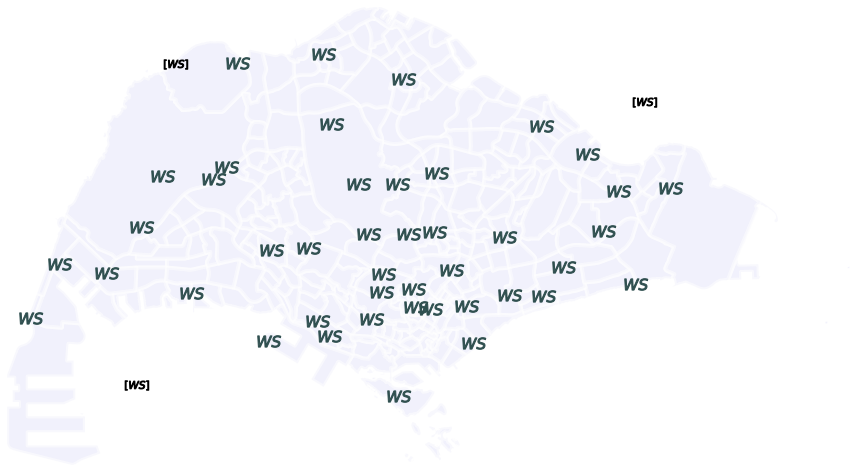

In [9]:
# plot
fig, ax = plt.subplots(figsize=FIGSIZE)

# Area layer
subzones.plot(
    linewidth=AREA_LINEWIDTH,
    edgecolor="white",
    color="lavender",
    alpha=0.55,
    zorder=1,
    ax=ax,
)

# Station layer
mapped_stations.plot(
    color="darkslategray", marker="$WS$", markersize=MSIZE, zorder=2, ax=ax
)

# Layer for unmapped stations
unmapped_stations = stations[~stations["id"].isin(ws_plotorder)]

unmapped_stations.plot(
    color="black", marker="$[WS]$", markersize=MSIZE, zorder=3, ax=ax
)


plt.axis("off")
plt.tight_layout()
plt.margins(0, 0)
plt.savefig(
    os.path.join(SAVEPATH, "ws-mapping-vanilla.pdf"),
    dpi=DPI,
    bbox_inches="tight",
    pad_inches=0,
)

#### Visual validation plot

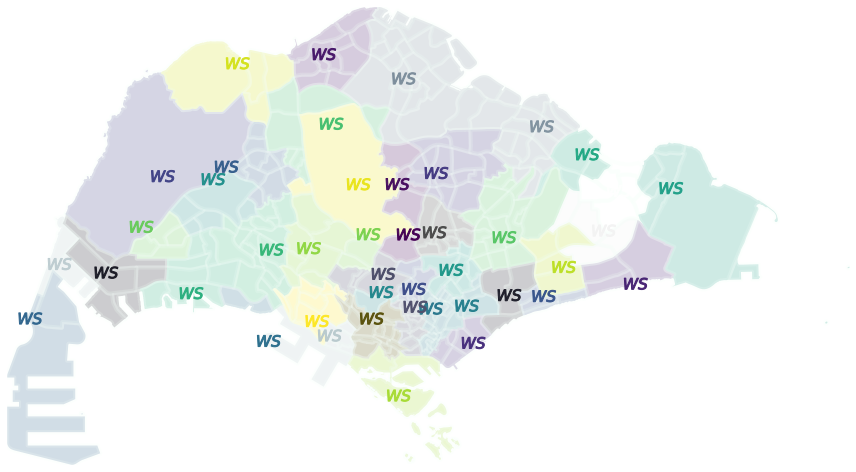

In [10]:
fig, ax = plt.subplots(figsize=FIGSIZE)

# Area layer
subzones.plot(
    column="weather_station",
    categories=ws_plotorder,
    cmap=CM,
    alpha=0.22,
    linewidth=AREA_LINEWIDTH,
    edgecolor="mintcream",
    zorder=1,
    ax=ax,
)

# Station layer
mapped_stations.plot(
    column="id",
    categories=ws_plotorder,
    marker="$WS$",
    markersize=MSIZE,
    cmap=CM,
    alpha=1,
    zorder=2,
    ax=ax,
)

plt.margins(0, 0)
plt.axis("off")
plt.tight_layout()
# Lost the color scheme
# plt.savefig(os.path.join(SAVEPATH, 'ws-mapping-validation.pdf'), dpi=DPI, bbox_inches='tight', pad_inches=0)

### Visual validation by lines

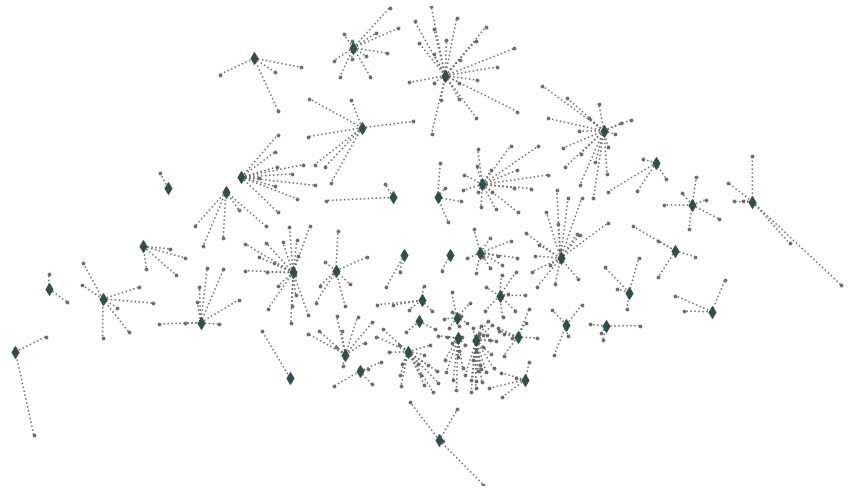

In [22]:
fig, ax = plt.subplots(figsize=FIGSIZE)

mapped_stations.plot(
    figsize=FIGSIZE, marker="d", markersize=70, color="darkslategray", ax=ax, zorder=2
)

for id1, slat, slong in zip(
    mapped_stations["id"], mapped_stations["lat"], mapped_stations["long"]
):
    for id2, dlat, dlong in zip(
        subzones["weather_station"], subzones["lat"], subzones["long"]
    ):
        if id1 == id2:
            plt.plot(
                [slong, dlong],
                [slat, dlat],
                marker="H",
                color="dimgray",
                linestyle=":",
                markersize=3,
                zorder=1,
            )

plt.margins(0.01, 0)
plt.axis("off")
plt.tight_layout()
plt.savefig(
    os.path.join(SAVEPATH, "ws-mapping-validation2.pdf"),
    dpi=DPI,
    bbox_inches="tight",
    pad_inches=0,
)